# Multilabel Classification - Music Emotions

## 1. Pendahuluan

Proyek ini bertujuan untuk mengklasifikasikan emosi musik
menggunakan metode Multilabel Classification.

Dataset Music Emotions digunakan karena satu data musik
dapat memiliki lebih dari satu kategori emosi.

## Algoritma
Random Forest dengan MultiOutputClassifier.

## Tujuan
1. Memahami proses Multilabel Classification.
2. Melakukan pengolahan dataset.
3. Melatih model Random Forest.
4. Mengevaluasi hasil klasifikasi.

## 2. Import Library

Mengimpor library yang diperlukan untuk membaca dataset,
mengolah data, membangun model, dan mengevaluasi hasil.

In [1]:
# Pengolahan data
import pandas as pd
import numpy as np

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset ARFF
from scipy.io import arff

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier

# Evaluasi model
from sklearn.metrics import (
    accuracy_score,
    hamming_loss,
    f1_score,
    classification_report
)

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


## 3. Memuat Dataset

Dataset Music Emotions memiliki karakteristik audio dan
label emosi musik. File dibaca menggunakan library SciPy,
kemudian diubah menjadi DataFrame Pandas.

In [2]:
# Membaca file dataset ARFF
data, meta = arff.loadarff("dataset/file3a6c5cb35bac.arff")

# Mengubah dataset menjadi DataFrame
df = pd.DataFrame(data)

# Mengubah nilai bytes menjadi string
for kolom in df.select_dtypes(include=["object"]).columns:
    df[kolom] = df[kolom].apply(
        lambda nilai: nilai.decode("utf-8")
        if isinstance(nilai, bytes) else nilai
    )

# Menampilkan informasi dataset
print("Dataset berhasil dimuat!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Dataset berhasil dimuat!
Jumlah baris: 593
Jumlah kolom: 78


,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed.suprised,happy.pleased,relaxing.calm,quiet.still,sad.lonely,angry.aggresive
0,0.034741,0.089665,0.091225,-73.302422,6.215179,0.615074,2.037160,0.804065,1.301409,0.558576,...,2.0,0.245457,0.105065,0.405399,FALSE,TRUE,TRUE,FALSE,FALSE,FALSE
1,0.081374,0.272747,0.085733,-62.584437,3.183163,-0.218145,0.163038,0.620251,0.458514,0.041426,...,2.0,0.343547,0.276366,0.710924,TRUE,FALSE,FALSE,FALSE,FALSE,TRUE
2,0.110545,0.273567,0.084410,-65.235325,2.794964,0.639047,1.281297,0.757896,0.489412,0.627636,...,3.0,0.188693,0.045941,0.457372,FALSE,TRUE,FALSE,FALSE,FALSE,TRUE
3,0.042481,0.199281,0.093447,-80.305152,5.824409,0.648848,1.754870,1.495532,0.739909,0.809644,...,2.0,0.102839,0.241934,0.351009,FALSE,FALSE,TRUE,FALSE,FALSE,FALSE
4,0.074550,0.140880,0.079789,-93.697749,5.543229,1.064262,0.899152,0.890336,0.702328,0.490685,...,2.0,0.195196,0.310801,0.683817,FALSE,FALSE,FALSE,TRUE,FALSE,FALSE


In [3]:
# Melihat informasi dataset
df.info()

# Melihat nama seluruh kolom
print("\nDaftar nama kolom:")
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 593 entries, 0 to 592
Data columns (total 78 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Mean_Acc1298_Mean_Mem40_Centroid  593 non-null    float64
 1   Mean_Acc1298_Mean_Mem40_Rolloff   593 non-null    float64
 2   Mean_Acc1298_Mean_Mem40_Flux      593 non-null    float64
 3   Mean_Acc1298_Mean_Mem40_MFCC_0    593 non-null    float64
 4   Mean_Acc1298_Mean_Mem40_MFCC_1    593 non-null    float64
 5   Mean_Acc1298_Mean_Mem40_MFCC_2    593 non-null    float64
 6   Mean_Acc1298_Mean_Mem40_MFCC_3    593 non-null    float64
 7   Mean_Acc1298_Mean_Mem40_MFCC_4    593 non-null    float64
 8   Mean_Acc1298_Mean_Mem40_MFCC_5    593 non-null    float64
 9   Mean_Acc1298_Mean_Mem40_MFCC_6    593 non-null    float64
 10  Mean_Acc1298_Mean_Mem40_MFCC_7    593 non-null    float64
 11  Mean_Acc1298_Mean_Mem40_MFCC_8    593 non-null    float64
 12  Mean_Acc1298_Mean_M

In [4]:
# Melihat enam kolom terakhir
print("Enam kolom terakhir:")

for kolom in df.columns[-6:]:
    print(f"\n{kolom}")
    print(df[kolom].value_counts(dropna=False))

Enam kolom terakhir:

amazed.suprised
amazed.suprised
FALSE    420
TRUE     173
Name: count, dtype: int64

happy.pleased
happy.pleased
FALSE    427
TRUE     166
Name: count, dtype: int64

relaxing.calm
relaxing.calm
FALSE    329
TRUE     264
Name: count, dtype: int64

quiet.still
quiet.still
FALSE    445
TRUE     148
Name: count, dtype: int64

sad.lonely
sad.lonely
FALSE    425
TRUE     168
Name: count, dtype: int64

angry.aggresive
angry.aggresive
FALSE    404
TRUE     189
Name: count, dtype: int64


## 4. Data Preprocessing

Pada tahap ini, label emosi musik dikonversi menjadi
nilai numerik. Nilai FALSE diubah menjadi 0 dan TRUE
diubah menjadi 1 agar dapat diproses oleh algoritma
Machine Learning.

In [5]:
# Mengambil enam kolom label terakhir
label_columns = df.columns[-6:].tolist()

# Menampilkan nama label
print("Enam label emosi:")
for kolom in label_columns:
    print(kolom)

Enam label emosi:
amazed.suprised
happy.pleased
relaxing.calm
quiet.still
sad.lonely
angry.aggresive


In [6]:
# Menyalin enam kolom label
y = df[label_columns].copy()

# Mengubah FALSE menjadi 0 dan TRUE menjadi 1
for kolom in label_columns:
    y[kolom] = (
        y[kolom]
        .astype(str)
        .str.strip()
        .str.upper()
        .map({"FALSE": 0, "TRUE": 1})
    )

# Memeriksa hasil konversi
print("Hasil konversi label:")
display(y.head())

print("\nJumlah nilai kosong:")
print(y.isnull().sum().sum())

print("\nNilai unik setiap label:")
print(y.nunique())

Hasil konversi label:


,amazed.suprised,happy.pleased,relaxing.calm,quiet.still,sad.lonely,angry.aggresive
0,0,1,1,0,0,0
1,1,0,0,0,0,1
2,0,1,0,0,0,1
3,0,0,1,0,0,0
4,0,0,0,1,0,0



Jumlah nilai kosong:
0

Nilai unik setiap label:
amazed.suprised    2
happy.pleased      2
relaxing.calm      2
quiet.still        2
sad.lonely         2
angry.aggresive    2
dtype: int64


In [7]:
# Mengambil seluruh kolom fitur
X = df.drop(columns=label_columns).copy()

# Memastikan fitur berupa angka
X = X.apply(pd.to_numeric, errors="coerce")

# Menampilkan ukuran data
print("Jumlah fitur:", X.shape[1])
print("Jumlah label:", y.shape[1])
print("Jumlah baris:", len(X))

print("\nJumlah NaN pada fitur:", X.isnull().sum().sum())
print("Jumlah NaN pada label:", y.isnull().sum().sum())

Jumlah fitur: 72
Jumlah label: 6
Jumlah baris: 593

Jumlah NaN pada fitur: 0
Jumlah NaN pada label: 0


## 5. Pembagian Data Training dan Testing

Dataset dibagi menjadi dua bagian, yaitu 80% data training
dan 20% data testing.

Data training digunakan untuk melatih model, sedangkan
data testing digunakan untuk menguji kemampuan model
dalam memprediksi beberapa label emosi musik.

In [8]:
# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Menampilkan hasil pembagian data
print("Pembagian data berhasil!")

print("\nData Training:")
print("Jumlah:", X_train.shape[0])

print("\nData Testing:")
print("Jumlah:", X_test.shape[0])

print("\nJumlah fitur:", X_train.shape[1])
print("Jumlah label:", y_train.shape[1])

Pembagian data berhasil!

Data Training:
Jumlah: 474

Data Testing:
Jumlah: 119

Jumlah fitur: 72
Jumlah label: 6


## 6. Pembuatan Model Random Forest

Algoritma Random Forest digunakan untuk melakukan
klasifikasi emosi musik.

Model dikombinasikan dengan MultiOutputClassifier
agar dapat memprediksi enam label emosi sekaligus.

In [9]:
# Membuat model Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Menggabungkan dengan MultiOutputClassifier
model = MultiOutputClassifier(random_forest)

print("Model Random Forest berhasil dibuat!")

Model Random Forest berhasil dibuat!


## 7. Training Model

Pada tahap ini, model Random Forest dilatih menggunakan
data training. MultiOutputClassifier akan membuat model
untuk memprediksi masing-masing dari enam label emosi musik.

In [10]:
# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Training model berhasil!")

Training model berhasil!


## 8. Prediksi Model

Model yang telah dilatih digunakan untuk memprediksi
label emosi pada data testing.

In [11]:
# Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# Mengubah hasil prediksi menjadi DataFrame
y_pred = pd.DataFrame(
    y_pred,
    columns=label_columns,
    index=y_test.index
)

print("Prediksi berhasil dilakukan!")

# Menampilkan lima hasil prediksi
display(y_pred.head())

Prediksi berhasil dilakukan!


,amazed.suprised,happy.pleased,relaxing.calm,quiet.still,sad.lonely,angry.aggresive
30,0,1,1,0,0,0
76,0,1,1,0,0,0
227,0,0,1,0,0,0
424,0,1,1,0,0,0
184,1,0,0,0,0,1


In [12]:
# Menampilkan label sebenarnya
print("Label Aktual:")
display(y_test.head())

# Menampilkan label hasil prediksi
print("Label Prediksi:")
display(y_pred.head())

Label Aktual:


,amazed.suprised,happy.pleased,relaxing.calm,quiet.still,sad.lonely,angry.aggresive
30,0,0,0,0,0,1
76,0,1,1,0,0,0
227,1,0,0,0,0,1
424,0,1,1,0,0,0
184,1,0,0,0,0,0


Label Prediksi:


,amazed.suprised,happy.pleased,relaxing.calm,quiet.still,sad.lonely,angry.aggresive
30,0,1,1,0,0,0
76,0,1,1,0,0,0
227,0,0,1,0,0,0
424,0,1,1,0,0,0
184,1,0,0,0,0,1


## 9. Evaluasi Model

Evaluasi dilakukan untuk mengetahui performa model
dalam memprediksi beberapa label emosi musik.

Metrik evaluasi yang digunakan:
1. Subset Accuracy
2. Hamming Loss
3. Micro F1-Score
4. Macro F1-Score

In [13]:
# Menghitung Subset Accuracy
subset_accuracy = accuracy_score(y_test, y_pred)

# Menghitung Hamming Loss
hamming = hamming_loss(y_test, y_pred)

# Menghitung Micro F1-Score
micro_f1 = f1_score(
    y_test, y_pred,
    average="micro",
    zero_division=0
)

# Menghitung Macro F1-Score
macro_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Menampilkan hasil evaluasi
print("HASIL EVALUASI MODEL")
print("====================")
print(f"Subset Accuracy : {subset_accuracy:.4f}")
print(f"Hamming Loss    : {hamming:.4f}")
print(f"Micro F1-Score  : {micro_f1:.4f}")
print(f"Macro F1-Score  : {macro_f1:.4f}")

HASIL EVALUASI MODEL
Subset Accuracy : 0.3277
Hamming Loss    : 0.1765
Micro F1-Score  : 0.6881
Macro F1-Score  : 0.6579


In [14]:
# Menampilkan laporan klasifikasi setiap label
print("CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_columns,
        zero_division=0
    )
)

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

amazed.suprised       0.69      0.50      0.58        36
  happy.pleased       0.67      0.24      0.36        33
  relaxing.calm       0.72      0.91      0.80        53
    quiet.still       0.78      0.91      0.84        23
     sad.lonely       0.77      0.55      0.64        31
angry.aggresive       0.82      0.66      0.73        41

      micro avg       0.74      0.64      0.69       217
      macro avg       0.74      0.63      0.66       217
   weighted avg       0.74      0.64      0.66       217
    samples avg       0.68      0.65      0.63       217



## 11. Kesimpulan

Berdasarkan hasil penelitian, model Multilabel Classification
menggunakan algoritma Random Forest dengan MultiOutputClassifier
berhasil melakukan klasifikasi terhadap enam kategori emosi musik.

Hasil evaluasi menunjukkan bahwa model memperoleh Micro F1-Score
sebesar 0.69 dan Macro F1-Score sebesar 0.66.

Label Quiet Still memperoleh F1-Score tertinggi sebesar 0.84,
sedangkan Happy Pleased memperoleh F1-Score terendah sebesar 0.36.

Dengan demikian, model mampu mengenali beberapa kategori emosi
musik dengan cukup baik, tetapi masih memerlukan peningkatan
agar hasil klasifikasi lebih merata pada seluruh label.

## 10. Visualisasi Hasil Evaluasi

Visualisasi digunakan untuk membandingkan jumlah
prediksi benar dan salah pada setiap label emosi.

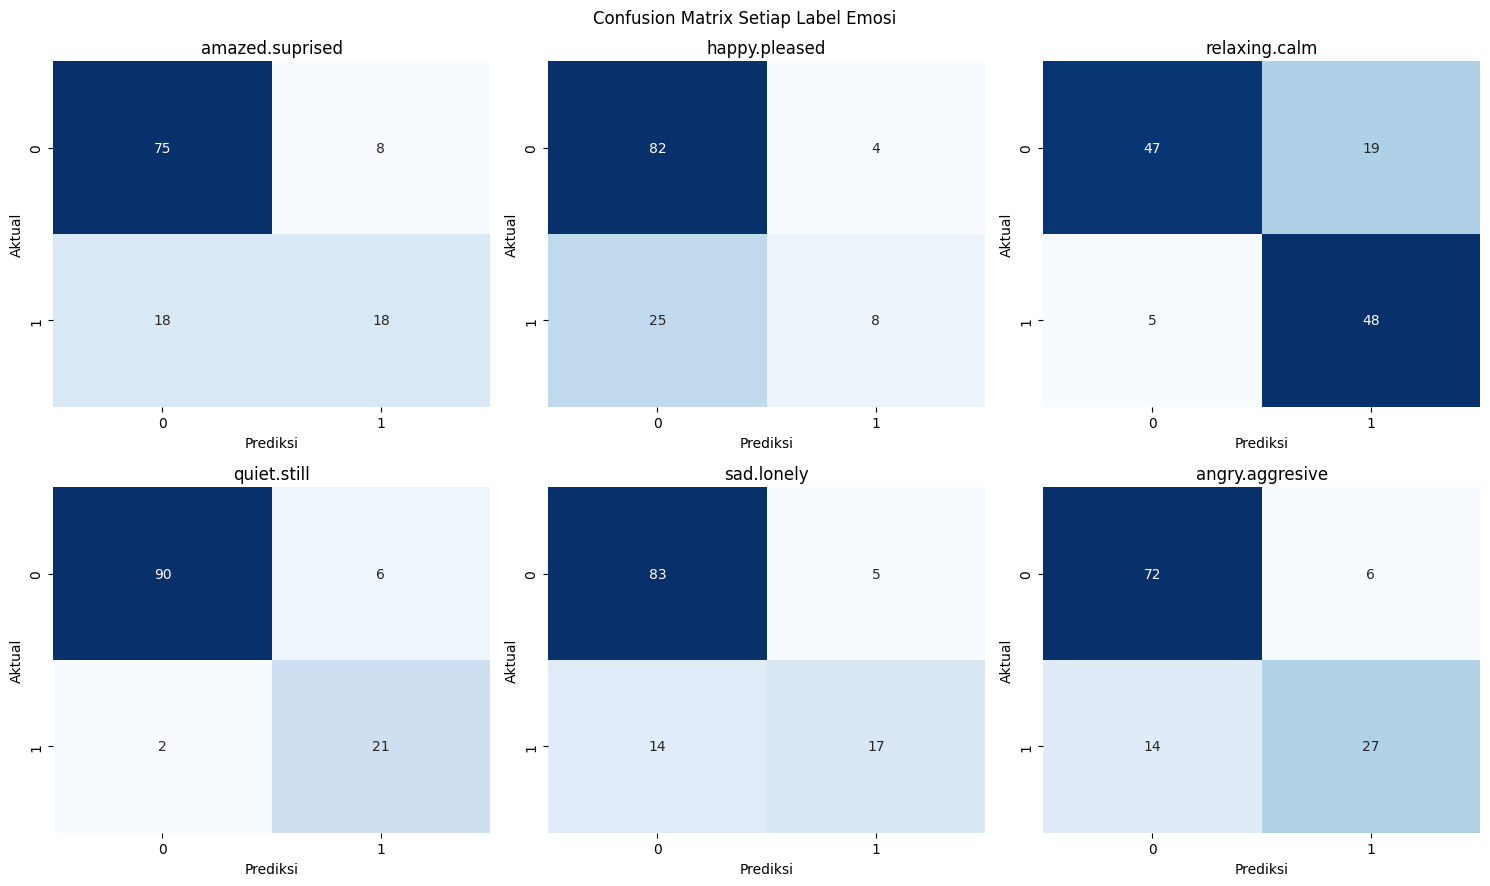

In [15]:
from sklearn.metrics import multilabel_confusion_matrix

# Membuat confusion matrix untuk setiap label
matrices = multilabel_confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flatten()):
    sns.heatmap(
        matrices[i],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(label_columns[i])
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.suptitle("Confusion Matrix Setiap Label Emosi")
plt.tight_layout()
plt.show()